In [1]:
import cell2cell as c2c
import liana as li

import pandas as pd

import decoupler as dc

import matplotlib.pyplot as plt
import plotnine as p9
import seaborn as sns

%matplotlib inline

In [2]:
import logging
logging.disable(logging.WARNING) # This is to avoid too many logs because of GSEApy

import warnings
warnings.filterwarnings('ignore')

In [3]:
#working env
import os
os.chdir(r'\\isdsyn1-1.isd.med.uni-muenchen.de\BD-Bernhagen\Simon Ebert\snRNAseq_Python_env_normalMT')
os.listdir()
data_folder = '//isdsyn1-1.isd.med.uni-muenchen.de/BD-Bernhagen/Simon Ebert/snRNAseq_Python_env_normalMT/Ms_subset/cell2cell_tensor/output/quickstart/'
output_folder = '//isdsyn1-1.isd.med.uni-muenchen.de/BD-Bernhagen/Simon Ebert/snRNAseq_Python_env_normalMT/Ms_subset/cell2cell_tensor/output/'
c2c.io.directories.create_directory(data_folder)
c2c.io.directories.create_directory(output_folder)

//isdsyn1-1.isd.med.uni-muenchen.de/BD-Bernhagen/Simon Ebert/snRNAseq_Python_env_normalMT/Ms_subset/cell2cell_tensor/output/quickstart/ already exists.
//isdsyn1-1.isd.med.uni-muenchen.de/BD-Bernhagen/Simon Ebert/snRNAseq_Python_env_normalMT/Ms_subset/cell2cell_tensor/output/ already exists.


In [4]:
from matplotlib.pyplot import rc_context
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

In [5]:
factors = c2c.io.load_tensor_factors(output_folder + 'Loadings.xlsx')

In [6]:
lr_pairs = li.resource.select_resource('mouseconsensus')
lr_pairs.head()

,ligand,receptor
31371,Dll1,Notch1
31372,Dll1,Notch2
31373,Dll1,Notch4
31374,Dll1,Notch3
31375,Nrg2,Erbb2_Erbb3


In [7]:
lr_list = ['^'.join(row) for idx, row in lr_pairs.iterrows()] 

In [8]:
organism = 'mouse' # For the COVID-19 data analyzed with LIANA+Tensor-cell2cell
pathwaydb = 'GOBP' # KEGG Pathways

In [9]:
lr_set = c2c.external.generate_lr_geneset(lr_list,
                                          complex_sep='_',
                                          lr_sep='^',
                                          organism=organism,
                                          pathwaydb=pathwaydb,
                                          readable_name=True,
                                          output_folder=output_folder
                                          )

In [10]:
lr_loadings = factors['Ligand-Receptor Pairs']

In [11]:
%%time
pvals, scores, gsea_df = c2c.external.run_gsea(loadings=lr_loadings, 
                                               lr_set=lr_set,
                                               output_folder=output_folder,
                                               weight=1,
                                               min_size=15,
                                               permutations=999,
                                               processes=6,
                                               random_state=6,
                                               significance_threshold=0.05,
                                              )

//isdsyn1-1.isd.med.uni-muenchen.de/BD-Bernhagen/Simon Ebert/snRNAseq_Python_env_normalMT/Ms_subset/cell2cell_tensor/output/ already exists.


100%|██████████| 8/8 [01:07<00:00,  8.43s/it]


CPU times: total: 1min 10s
Wall time: 1min 9s


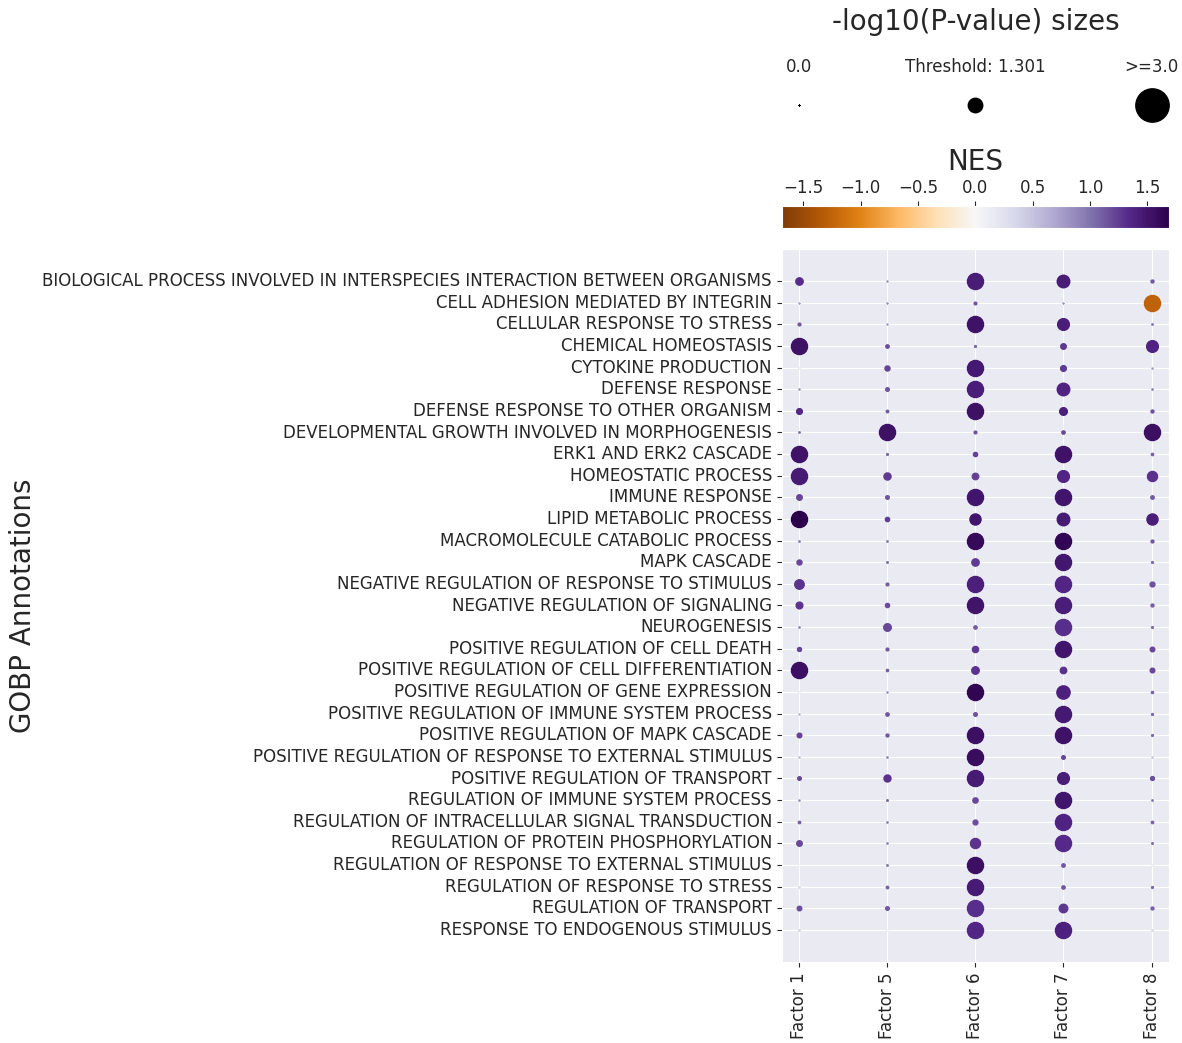

In [12]:
with sns.axes_style("darkgrid"):
    dotplot = c2c.plotting.pval_plot.generate_dot_plot(pval_df=pvals,
                                                       score_df=scores,
                                                       significance=0.05,
                                                       xlabel='',
                                                       ylabel='{} Annotations'.format(pathwaydb),
                                                       cbar_title='NES',
                                                       cmap='PuOr',
                                                       figsize=(5, 12),
                                                       label_size=20,
                                                       title_size=20,
                                                       tick_size=12,
                                                       filename=output_folder + '/GSEA-Dotplot.pdf'
                                                      )

In [13]:
gsea_df

,Factor,Term,NES,P-value,Adj. P-value
0,Factor 1,LIPID METABOLIC PROCESS,1.689945,0.001000,0.035666
1,Factor 1,POSITIVE REGULATION OF CELL DIFFERENTIATION,1.556245,0.001000,0.035666
2,Factor 1,CHEMICAL HOMEOSTASIS,1.532310,0.001000,0.035666
3,Factor 1,ERK1 AND ERK2 CASCADE,1.521104,0.001002,0.035666
4,Factor 1,HOMEOSTATIC PROCESS,1.457376,0.001001,0.035666
...,...,...,...,...,...
1379,Factor 8,RESPONSE TO TRANSFORMING GROWTH FACTOR BETA,0.726334,0.954910,1.000000
1380,Factor 8,HEART DEVELOPMENT,0.708767,0.988989,1.000000
1381,Factor 8,BLOOD VESSEL MORPHOGENESIS,0.703817,0.997998,1.000000
1382,Factor 8,TRANSMEMBRANE RECEPTOR PROTEIN SERINE THREONIN...,0.666711,0.991976,1.000000


In [14]:
gsea_df.loc[(gsea_df['Adj. P-value'] < 0.05) & (gsea_df['NES'] > 0.)]

,Factor,Term,NES,P-value,Adj. P-value
0,Factor 1,LIPID METABOLIC PROCESS,1.689945,0.001000,0.035666
1,Factor 1,POSITIVE REGULATION OF CELL DIFFERENTIATION,1.556245,0.001000,0.035666
2,Factor 1,CHEMICAL HOMEOSTASIS,1.532310,0.001000,0.035666
3,Factor 1,ERK1 AND ERK2 CASCADE,1.521104,0.001002,0.035666
4,Factor 1,HOMEOSTATIC PROCESS,1.457376,0.001001,0.035666
692,Factor 5,DEVELOPMENTAL GROWTH INVOLVED IN MORPHOGENESIS,1.539414,0.001005,0.035666
865,Factor 6,POSITIVE REGULATION OF GENE EXPRESSION,1.642807,0.001000,0.035666
866,Factor 6,MACROMOLECULE CATABOLIC PROCESS,1.605723,0.001001,0.035666
867,Factor 6,POSITIVE REGULATION OF RESPONSE TO EXTERNAL ST...,1.572958,0.001002,0.035666
868,Factor 6,POSITIVE REGULATION OF MAPK CASCADE,1.553747,0.001000,0.035666


In [15]:
gsea_df.loc[(gsea_df['Adj. P-value'] < 0.05) & (gsea_df['NES'] < 0.)]

,Factor,Term,NES,P-value,Adj. P-value
1218,Factor 8,CELL ADHESION MEDIATED BY INTEGRIN,-1.255639,0.001,0.035666


In [16]:
gsea_df=gsea_df[gsea_df['Term'].str.contains('STRESS|CYTOKINE|STIMULUS|STRESS|IMMUNE')]
gsea_df=gsea_df[~gsea_df['Term'].str.contains('NEGATIVE')]

In [17]:
gsea_df = gsea_df.loc[(gsea_df['Factor'] == "Factor 4") | (gsea_df['Factor'] == "Factor 6")| (gsea_df['Factor'] == "Factor 5")| (gsea_df['Factor'] == "Factor 8")]


In [18]:
gsea_df

,Factor,Term,NES,P-value,Adj. P-value
526,Factor 4,IMMUNE RESPONSE,1.284714,0.017017,0.196263
543,Factor 4,CYTOKINE PRODUCTION,1.159737,0.151151,0.506521
547,Factor 4,REGULATION OF RESPONSE TO STRESS,1.144123,0.135135,0.484526
565,Factor 4,IMMUNE SYSTEM DEVELOPMENT,1.087245,0.287287,0.638181
572,Factor 4,RESPONSE TO CYTOKINE,1.068049,0.332665,0.679431
585,Factor 4,CELLULAR RESPONSE TO STRESS,1.038581,0.372372,0.717232
614,Factor 4,REGULATION OF RESPONSE TO EXTERNAL STIMULUS,0.962873,0.608609,0.863562
623,Factor 4,IMMUNE EFFECTOR PROCESS,0.936649,0.618474,0.870090
639,Factor 4,REGULATION OF IMMUNE SYSTEM PROCESS,0.891102,0.812813,0.967268
641,Factor 4,POSITIVE REGULATION OF IMMUNE SYSTEM PROCESS,0.888999,0.778779,0.955058


In [19]:
pval_pivot = gsea_df.pivot(index="Term", columns="Factor", values="Adj. P-value").fillna(1.)
scores_new = gsea_df.pivot(index="Term", columns="Factor", values="NES").fillna(0)

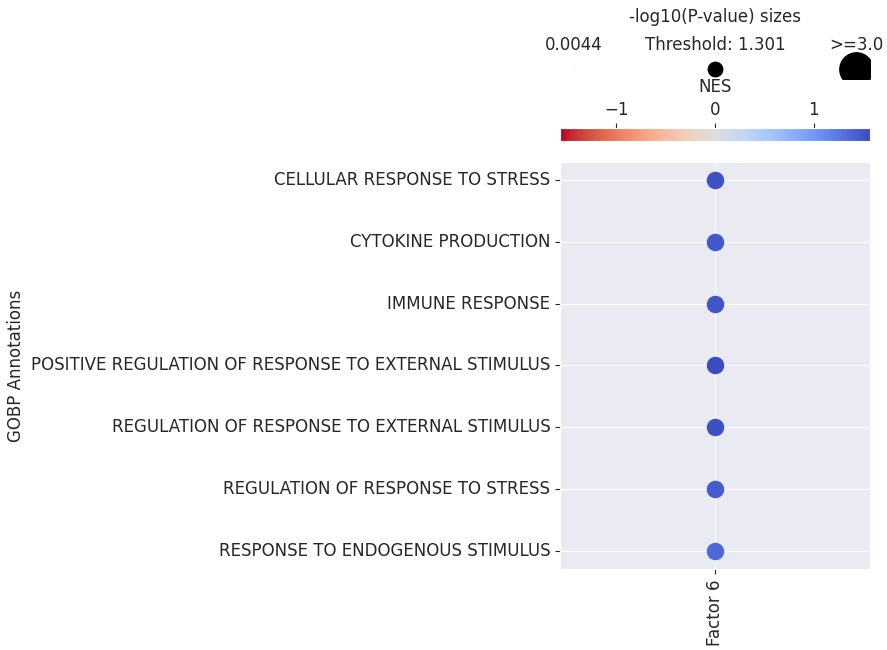

In [20]:
pathway_label = '{} Annotations'.format(pathwaydb)
fig_filename = output_folder + '/GSEA-Dotplot.pdf'

with sns.axes_style("darkgrid"):
    dotplot = c2c.plotting.pval_plot.generate_dot_plot(pval_df=pval_pivot,
                                                      score_df=scores_new,
                                                      significance=0.05,
                                                      xlabel='',
                                                      ylabel='{} Annotations'.format(pathwaydb),
                                                      cbar_title='NES',
                                                      cmap='coolwarm_r',
                                                      figsize=(4,7),
                                                      label_size=12,
                                                      title_size=12,
                                                      tick_size=12,
                                                      filename=fig_filename,
                                                                                                           )

In [22]:
net = dc.get_progeny(organism='mouse', top=5000)

In [23]:
lr_progeny = li.rs.generate_lr_geneset(lr_pairs, net, lr_sep="^")
lr_progeny.head()

,source,interaction,weight
1,EGFR,Dll1^Notch1,-1.000584
42,NFkB,Dll1^Notch2,0.809955
73,NFkB,Dll1^Notch4,0.677967
87,Trail,Dll1^Notch4,0.725850
99,Hypoxia,Dll1^Notch3,1.049842


In [24]:
estimate, pvals =  dc.run_mlm(lr_loadings.transpose(), 
                              lr_progeny, 
                              source="source", 
                              target="interaction", 
                              min_n=5,

                              use_raw=False)

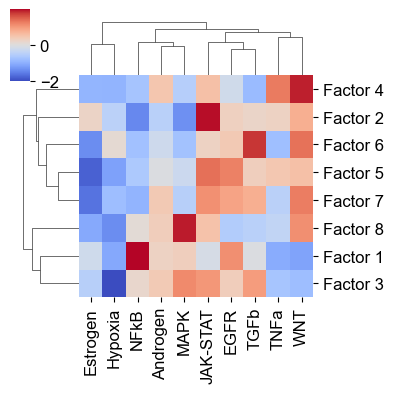

In [25]:
sns.clustermap(estimate, xticklabels=estimate.columns, cmap='coolwarm', z_score=4, figsize=(4,4))
plt.savefig(output_folder + '/PROGENy.pdf', dpi=300, bbox_inches='tight')

In [26]:
estimate
estimate.drop(columns=['Androgen', 'Estrogen'], inplace=True)

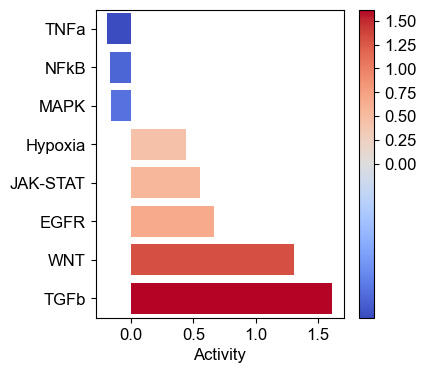

In [27]:
selected_factor = 'Factor 6'

dc.plot_barplot(estimate,
                selected_factor,
                vertical=True, 
                cmap='coolwarm', 
                figsize=(4, 4),
                save=output_folder + '/PROGENy6-{}.pdf'.format(selected_factor.replace(' ', '-')))

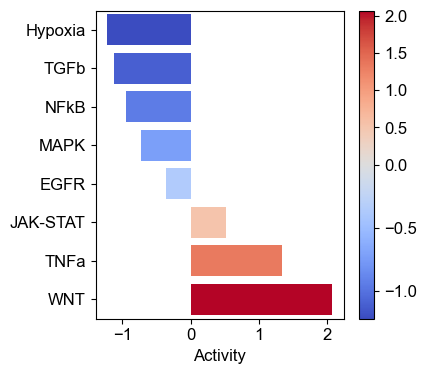

In [28]:
selected_factor = 'Factor 4'

dc.plot_barplot(estimate,
                selected_factor,
                vertical=True, 
                cmap='coolwarm', 
                figsize=(4, 4),
                save=output_folder + '/PROGENy6-{}.pdf'.format(selected_factor.replace(' ', '-')))

In [29]:
pathway = 'TGFb'
# loadings to long format
lr_loadings_long = lr_loadings.reset_index().melt(id_vars='index', var_name="Factor", value_name="Loadings").rename(columns={'index':'interaction'})
# join progeny weights and keep only NFkB pathway
lr_loadings_long = lr_loadings_long.merge(lr_progeny, on='interaction').query("source == '{}' and Factor == '{}'".format(pathway, selected_factor))
# add sign to the weights
lr_loadings_long['sign'] = lr_loadings_long['weight'].apply(lambda x: 'positive' if x > 0 else 'negative')
# keep only relevant interactions for labels
lr_loadings_long['relevant_interactions'] = lr_loadings_long.apply(lambda x: x['interaction'] if (x['Loadings'] > 0.025) and (x['weight'] > 2.5) else None, axis=1)
lr_loadings_long.head()

,interaction,Factor,Loadings,source,weight,sign,relevant_interactions
399,Adam10^Notch2,Factor 4,8.028863e-02,TGFb,1.250265,positive,None
413,Alcam^Nrp1,Factor 4,9.134541e-02,TGFb,-1.272273,negative,None
435,Col1a1^Itga5,Factor 4,9.809089e-45,TGFb,2.502455,positive,None
436,Cp^Slc40a1,Factor 4,4.467462e-02,TGFb,-1.515521,negative,None
440,Fbn1^Itga5,Factor 4,9.996833e-05,TGFb,1.844514,positive,None


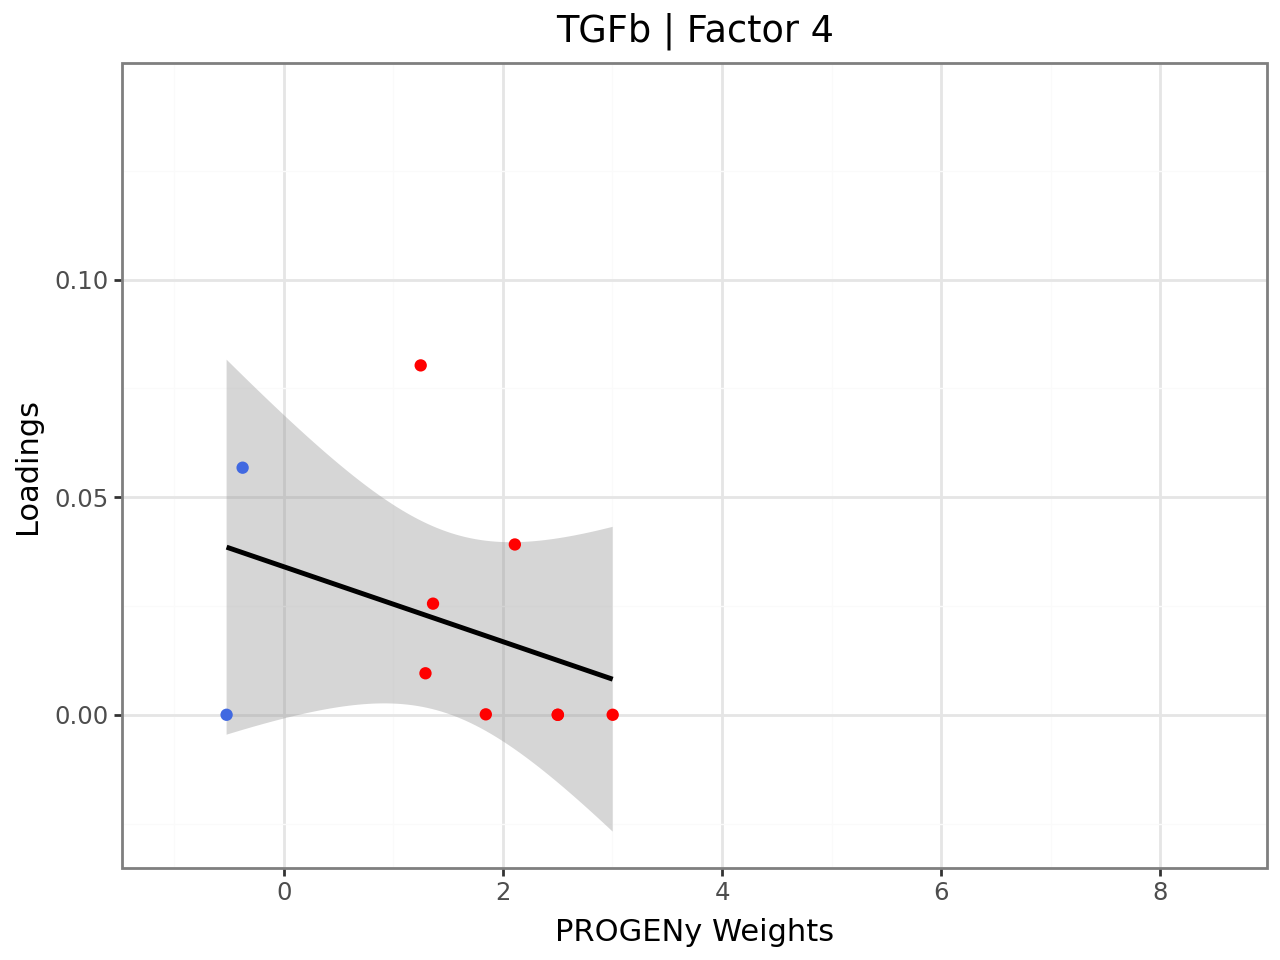

In [30]:
(p9.ggplot(lr_loadings_long,
           p9.aes(x='weight', y='Loadings')) +
 p9.geom_smooth(method='lm') + 
 p9.geom_point(p9.aes(colour='sign')) +
 p9.theme_bw() +
 p9.theme(legend_position='none') +
 p9.labs(title="{} | {}".format(pathway, selected_factor), x="PROGENy Weights", y="Loadings") +
 p9.scale_colour_manual(values=["royalblue", "red"]) +
 p9.geom_label(p9.aes(label='relevant_interactions'), size=8, nudge_y=0.05, nudge_x=0.05) + 
 p9.xlim(-1, 8.5)
 )